# CytoTRACE: real bone marrow, same-input R validation

Use the first 120 cells and **all 13,526 measured genes** of the original CytoTRACE `marrow_10x_expr` dataset. The stored expected scores were generated by the unmodified R `CytoTRACE` function at commit `f4ff6c0ab93cc704eef44e17adcd5c6baf09703a`, with `enableFast=FALSE`, one core, and no batch correction. This bounded case establishes numerical agreement; it is not evidence for all datasets or unimplemented batch/fast modes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pycytotrace import cytotrace_run
f = np.load('data/marrow_reference.npz')
result = cytotrace_run(f['counts'], gene_names=f['genes'].tolist(), cell_names=f['cells'].tolist())
np.testing.assert_allclose(result.cytotrace, f['scores'], atol=1e-10, rtol=1e-9)
print({'cells':len(result.cell_names), 'input_genes':f['counts'].shape[0], 'max_score_error':float(np.max(abs(result.cytotrace-f['scores'])))})

{'cells': 120, 'input_genes': 13526, 'max_score_error': 4.996003610813204e-16}


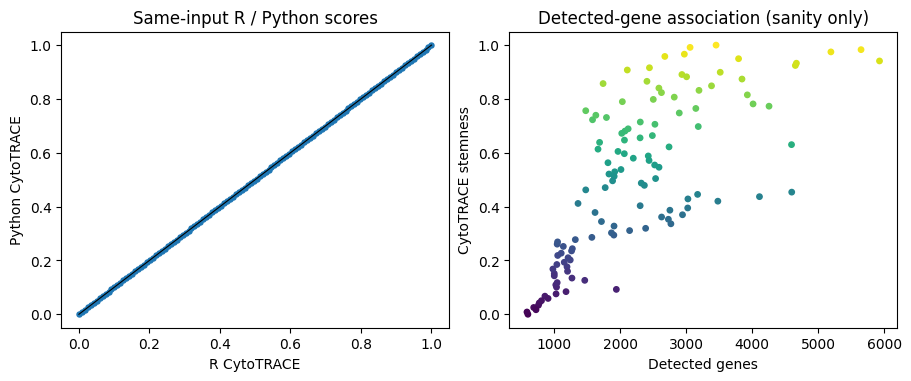

In [2]:
fig, axes = plt.subplots(1,2,figsize=(9,3.7),constrained_layout=True)
axes[0].scatter(f['scores'],result.cytotrace,s=13)
axes[0].plot([0,1],[0,1],color='black',linewidth=0.8)
axes[0].set(title='Same-input R / Python scores',xlabel='R CytoTRACE',ylabel='Python CytoTRACE')
axes[1].scatter(result.counts,result.cytotrace,c=result.cytotrace,cmap='viridis',s=15)
axes[1].set(title='Detected-gene association (sanity only)',xlabel='Detected genes',ylabel='CytoTRACE stemness')
plt.show()